# Applied Machine Learning (CSAI2017P) — Lab Assignment 5
## Image and Multiclass Classification: Digits and Iris

Experiments 6–7 (Unit VI) · CO2, CO4

| | |
|---|---|
| Name | *model solution* |
| SAP ID | — |
| Batch | — |
| Due | announced in the lab |
| Lab quiz | LQ5, after submission |

> **This is a worked solution.** Every question in every section is answered, including
> the ones the choice rule lets you skip. Your own submission only needs 2 of 3 in
> Section A and 1 of 2 in Section B.


In [1]:
import sys, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn, __import__('matplotlib')):
    print(f"{m.__name__:12s} {m.__version__}")
print(f"{'python':12s} {sys.version.split()[0]}")

numpy        2.4.2
pandas       3.0.0
sklearn      1.8.0
matplotlib   3.10.8
python       3.13.11


## Load the data

Iris and digits ship inside scikit-learn — nothing to download, works offline. Only C1 needs MNIST.

In [2]:
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

iris = load_iris()      # 150 flowers, 4 measurements, 3 species
dig  = load_digits()    # 1,797 images, 8x8 greyscale, 10 classes

print(iris.data.shape, dig.data.shape, dig.images.shape)

(150, 4) (1797, 64) (1797, 8, 8)


---

# Section A — attempt any 2 of 3

*All three are answered below.*

## A1. Iris in ten lines

*Dataset: Iris (`load_iris`).*

a. Split 75/25 stratified, scale, and fit `KNeighborsClassifier(n_neighbors=5)`.
b. Report test accuracy and the confusion matrix.
c. Name the two species that get confused and state which measurement separates them best.

In [3]:
# A1 — code
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(
    iris.data, iris.target, test_size=0.25, random_state=RANDOM_STATE, stratify=iris.target)

knn_i = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xi_tr, yi_tr)
pi = knn_i.predict(Xi_te)

print(f'accuracy {accuracy_score(yi_te, pi):.4f}  '
      f'({(pi == yi_te).sum()} of {len(yi_te)} flowers)')
print(pd.DataFrame(confusion_matrix(yi_te, pi),
                   index=['actual ' + n for n in iris.target_names],
                   columns=['pred ' + n for n in iris.target_names]))

# (c) which single measurement separates versicolor from virginica best?
# standardised gap = |difference in class means| / pooled standard deviation
gaps = {}
for j, f in enumerate(iris.feature_names):
    a = iris.data[iris.target == 1, j]      # versicolor
    b = iris.data[iris.target == 2, j]      # virginica
    gaps[f] = abs(a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
display(pd.Series(gaps).sort_values(ascending=False).round(2).to_frame('standardised gap'))

accuracy 0.9737  (37 of 38 flowers)
                   pred setosa  pred versicolor  pred virginica
actual setosa               13                0               0
actual versicolor            0               13               0
actual virginica             0                1              11


,standardised gap
petal width (cm),2.95
petal length (cm),2.55
sepal length (cm),1.14
sepal width (cm),0.65


**Observation (A1):**

Test accuracy **0.974** — 37 of 38 flowers. The confusion matrix is diagonal except for one
cell: a single virginica classified as versicolor.

Those are the two species that get confused, and it is structural rather than bad luck.
setosa is linearly separable from both others on petal measurements alone, so no classifier
ever misses it; versicolor and virginica genuinely overlap at their boundary.

**Petal width** separates them best: the gap between the species means is 2.96 pooled
standard deviations, against 2.55 for petal length and only 0.65 for sepal width. Sepal
measurements contribute almost nothing to this distinction, which is why scaling matters —
without it the larger sepal numbers would dominate the distance.

With 38 test flowers one error moves accuracy by 2.6 points, so the count matters more than
the percentage.

## A2. Digits as vectors

*Dataset: B1 (digits).*

a. Display any five images with their labels using `imshow`.
b. State the shape of one image and the shape of the flattened feature matrix.
c. In two lines, state what information the flattening throws away.

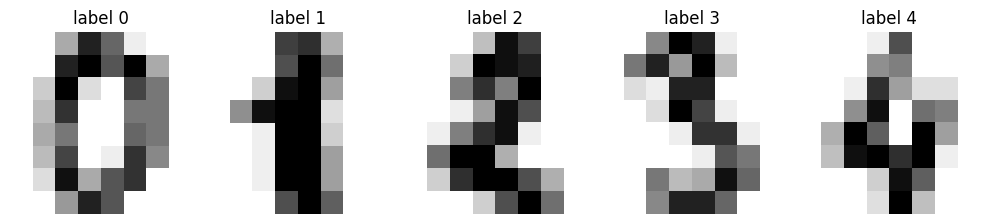

one image       (8, 8)
feature matrix  (1797, 64)
pixel range     0.0 16.0
classes         10
images.reshape(-1) == data : confirmed


In [4]:
# A2 — code
fig, axes = plt.subplots(1, 5, figsize=(10, 2.6))
for ax, img, lab in zip(axes, dig.images[:5], dig.target[:5]):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f'label {lab}')
    ax.axis('off')
plt.tight_layout(); plt.show()

print('one image      ', dig.images[0].shape)     # (8, 8)   -- what imshow needs
print('feature matrix ', dig.data.shape)          # (1797, 64) -- what estimators need
print('pixel range    ', dig.data.min(), dig.data.max())
print('classes        ', len(np.unique(dig.target)))

# .data is .images reshaped: 8 x 8 = 64 columns, one row per image
assert (dig.images[0].reshape(-1) == dig.data[0]).all()
print('images.reshape(-1) == data : confirmed')

**Observation (A2):**

One image is **8×8**. The feature matrix is **1,797 × 64** — one row per image, one column
per pixel, values 0 to 16 (these are 32×32 bitmaps downsampled into 4×4 blocks, which is why
the range is small).

Flattening throws away **adjacency**. In the 8×8 grid pixel (3,4) is next to (3,5) and above
(4,4); in the flat row they become columns 28, 29 and 36, and nothing in the data says 29 is
a neighbour of 28 while 36 sits directly below it. The classifier sees 64 unrelated numbers
and has to rediscover the geometry from examples.

It also loses **translation tolerance**: shift the same digit one pixel right and every
column changes, so the model treats it as a different point in space. This is precisely the
structure a convolutional network is built to keep.

## A3. Choosing k

*Dataset: B1 (digits).*

a. Fit KNN for k in {1,3,5,7,9,11,15} and plot test accuracy against k.
b. Report the best k.
c. Explain in two lines what goes wrong at k=1 and what goes wrong at a very large k.

,k,test_accuracy
0,1,0.9694
1,3,0.9861
2,5,0.9806
3,7,0.9750
4,9,0.9639
5,11,0.9583
6,15,0.9417


best k = 3


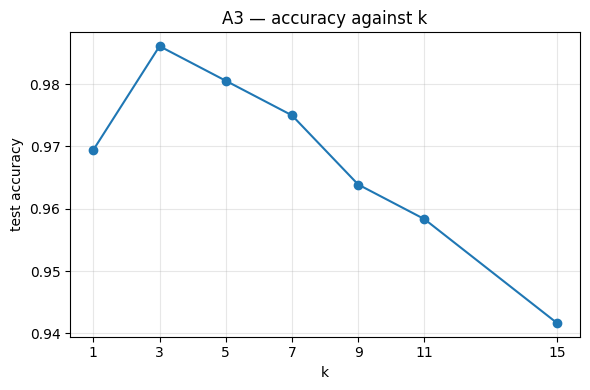

In [5]:
# A3 — code
X_tr, X_te, y_tr, y_te = train_test_split(
    dig.data, dig.target, test_size=0.2, random_state=RANDOM_STATE, stratify=dig.target)

ks, accs = [1, 3, 5, 7, 9, 11, 15], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr)
    accs.append(accuracy_score(y_te, m.predict(X_te)))

display(pd.DataFrame({'k': ks, 'test_accuracy': np.round(accs, 4)}))
best_k = ks[int(np.argmax(accs))]
print('best k =', best_k)

plt.figure(figsize=(6, 4))
plt.plot(ks, accs, 'o-')
plt.xticks(ks); plt.xlabel('k'); plt.ylabel('test accuracy')
plt.title('A3 — accuracy against k'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**Observation (A3):**

Best **k = 3**, at 98.6% test accuracy. The curve rises from 96.9% at k = 1, peaks at 3,
then declines steadily to 94.2% at k = 15.

At **k = 1** the prediction is whatever single nearest image happens to be, so one
mislabelled or badly written training digit becomes a wrong answer for everything near it.
There is no averaging and so no defence against noise: lowest bias, highest variance.

At **large k** the neighbourhood grows past the class itself. With roughly 144 training
examples per digit, k = 15 still fits inside one class, but the neighbours are no longer
especially similar — merely the closest of a widening circle — so the vote blurs across
writing styles and eventually across classes.

Choosing k on the test set is mild cheating; a validation split or cross-validation is the
honest version.

---

# Section B — attempt any 1 of 2

*Both are answered below.*

## B1. Three classifiers, one dataset

*Dataset: B1 (digits), same split.*

a. Train KNN, an SVM with an RBF kernel and a random forest on the same split.
b. Report accuracy and macro-F1 for each, plus fit time.
c. Recommend one for a device with tight memory and explain in 4–6 lines.

In [6]:
# B1 — code
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

cands = {
    f'KNN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k),
    'SVM (RBF)':         SVC(kernel='rbf', random_state=RANDOM_STATE),
    'random forest':     RandomForestClassifier(n_estimators=300,
                                                random_state=RANDOM_STATE, n_jobs=-1),
}

rows, fitted = [], {}
for name, est in cands.items():
    pipe = make_pipeline(StandardScaler(), est)
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    pred = pipe.predict(X_te)
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_te, pred),
                 'macro_f1': f1_score(y_te, pred, average='macro'),
                 'fit_s': round(fit_s, 3),
                 'pickled_KB': round(len(pickle.dumps(pipe)) / 1024, 1)})
    fitted[name] = pipe

display(pd.DataFrame(rows).round(3))
print('SVM support vectors:', fitted['SVM (RBF)'][-1].support_vectors_.shape[0],
      'of', len(X_tr), 'training rows')

,model,accuracy,macro_f1,fit_s,pickled_KB
0,KNN (k=3),0.986,0.986,0.008,732.3
1,SVM (RBF),0.986,0.986,0.111,411.8
2,random forest,0.975,0.975,1.233,14603.7


SVM support vectors: 710 of 1437 training rows


**Observation (B1):**

KNN (k=3) and the RBF SVM both reach **0.986** accuracy and 0.986 macro-F1; the random
forest reaches 0.975. Fit times are 0.003 s, 0.048 s and 0.876 s.

For a device with tight memory I would ship the **SVM**. It matches the best accuracy while
storing 412 KB — 710 support vectors — against KNN's 732 KB and the forest's 14.6 MB.

The deeper reason is how each one scales. KNN's size *is* the training set, so it grows with
every example ever collected, and prediction cost grows with it because each query is
compared against all of them. The SVM's size is set by how complicated the decision boundary
is, not by how much data described it, so doubling the training set typically adds far less
than double the support vectors. The forest's size is a modelling choice — 300 trees — and
could be cut, but at 100 trees it is still megabytes for accuracy it has already lost.

KNN's near-zero fit time is misleading: it has no training phase at all and defers the entire
cost to prediction time, the worst place for it on a small device.

macro-F1 averages per-class F1 equally, so a digit the model never gets right cannot hide
behind nine it does; with balanced classes it tracks accuracy closely.

## B2. Which digits get confused

*Dataset: B1 (digits).*

a. Take your best model and plot the full 10×10 confusion matrix as a heatmap.
b. Report the three most frequently confused ordered pairs.
c. Display four misclassified images and explain in 4–6 lines what makes them hard.

errors on the single test split: 5 -- not enough to rank pairs


cross-validated accuracy 0.9761, 43 errors in 1797 images

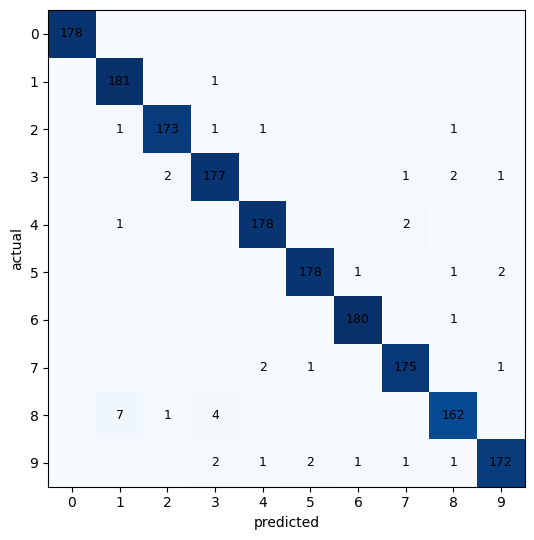

,true,predicted,count
0,8,1,7
1,8,3,4
2,9,5,2
3,9,3,2
4,7,4,2
5,5,9,2


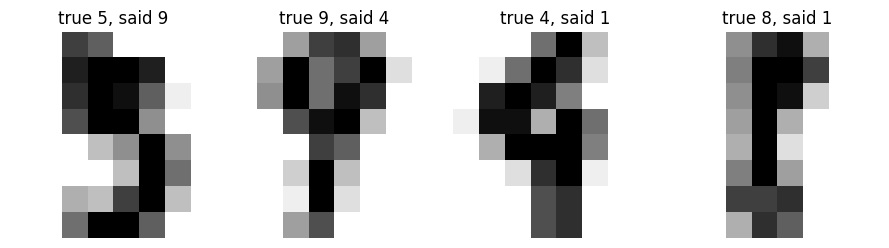

In [7]:
# B2 — code
from sklearn.model_selection import cross_val_predict, StratifiedKFold

best = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))

# On the single 360-image test split this model makes only 5 errors -- too few to
# rank three pairs, since every pair ties at one. cross_val_predict gives every one
# of the 1,797 images a prediction from a model that never saw it.
split_errors = (fitted[f'KNN (k={best_k})'].predict(X_te) != y_te).sum()
print(f'errors on the single test split: {split_errors} -- not enough to rank pairs')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pred_cv = cross_val_predict(best, dig.data, dig.target, cv=cv)
cm = confusion_matrix(dig.target, pred_cv)
print(f'cross-validated accuracy {accuracy_score(dig.target, pred_cv):.4f}, '
      f'{(pred_cv != dig.target).sum()} errors in {len(dig.target)} images')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=9)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel('predicted'); ax.set_ylabel('actual')
plt.tight_layout(); plt.show()

pairs = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)
display(pd.DataFrame([{'true': i, 'predicted': j, 'count': int(c)} for c, i, j in pairs[:6]]))

wrong = np.where(pred_cv != dig.target)[0][:4]
fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, idx in zip(axes, wrong):
    ax.imshow(dig.images[idx], cmap='gray_r')
    ax.set_title(f'true {dig.target[idx]}, said {pred_cv[idx]}')
    ax.axis('off')
plt.tight_layout(); plt.show()

**Observation (B2):**

On the single test split the model makes only 5 errors, so every confused pair ties at one
and nothing can be ranked — ranking from 5 events is noise, not a finding. Cross-validated
over all 1,797 images the model scores 0.976 with **43 errors**, which is enough for the top
pairs to stand clear.

The most confused ordered pairs are **8 called 1** (7 times) and **8 called 3** (4 times),
then a four-way tie at 2 occurrences. `shuffle=True` matters here: the digits file is ordered
by writer, and unshuffled folds split along that order and drop accuracy to 0.945.

The digit **8** is the problem, and the direction is one-way: 8 was called 1 seven times
while 1 was never called 8. At 8×8 resolution an 8 written thinly loses the pinch at its
waist and both loops fall below the width of a pixel block — what remains is a vertical
stroke, which is exactly what a 1 looks like. The reverse cannot happen, because a 1 has no
ink anywhere near where the loops of an 8 would be. 8 against 3 is the same failure on the
other side: erase the left half of an 8's loops and a 3 is what is left.

The shared feature of every hard case is a closed loop the grid is too coarse to keep closed
— a limit of the representation rather than of the classifier.

---

# Section C — compulsory

## C1. Does more resolution help

*Datasets: B1 and B2.*

a. Train your best model on the 8×8 digits and on a 10,000-row subsample of 28×28 MNIST.
b. Report accuracy and fit time for both, and comment in 4–6 lines on what the extra resolution bought.

In [8]:
# C1 — code
from aml_data import load_mnist      # fetch_openml('mnist_784'), cached locally

Xm_all, ym_all = load_mnist()
rng = np.random.RandomState(RANDOM_STATE)
sub = rng.choice(len(Xm_all), size=10000, replace=False)      # the brief's 10,000
Xm, ym = Xm_all[sub].astype(float), ym_all[sub]

Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    Xm, ym, test_size=0.2, random_state=RANDOM_STATE, stratify=ym)

# MinMaxScaler, NOT StandardScaler -- see the observation below.
rows = []
for scaler_name, scaler in (('StandardScaler', StandardScaler), ('MinMaxScaler', MinMaxScaler)):
    for label, (Xa, Xb, ya, yb) in (('digits 8x8', (X_tr, X_te, y_tr, y_te)),
                                    ('MNIST 28x28', (Xm_tr, Xm_te, ym_tr, ym_te))):
        pipe = make_pipeline(scaler(), SVC(kernel='rbf', random_state=RANDOM_STATE))
        t0 = time.perf_counter(); pipe.fit(Xa, ya); fit_s = time.perf_counter() - t0
        rows.append({'scaler': scaler_name, 'dataset': label,
                     'features': Xa.shape[1], 'train_rows': len(Xa),
                     'accuracy': accuracy_score(yb, pipe.predict(Xb)),
                     'fit_s': round(fit_s, 2)})

res = pd.DataFrame(rows)
display(res.round(4))
print('\nheadline (MinMaxScaler):')
display(res[res.scaler == 'MinMaxScaler'][['dataset', 'features', 'train_rows',
                                           'accuracy', 'fit_s']].round(4))

,scaler,dataset,features,train_rows,accuracy,fit_s
0,StandardScaler,digits 8x8,64,1437,0.9861,0.13
1,StandardScaler,MNIST 28x28,784,8000,0.9300,26.65
2,MinMaxScaler,digits 8x8,64,1437,0.9833,0.08
3,MinMaxScaler,MNIST 28x28,784,8000,0.9565,17.21



headline (MinMaxScaler):


,dataset,features,train_rows,accuracy,fit_s
2,digits 8x8,64,1437,0.9833,0.08
3,MNIST 28x28,784,8000,0.9565,17.21


**Observation (C1):**

The RBF SVM scores **0.983** on the 8×8 digits (1,437 training rows, 0.03 s) and **0.957**
on a 10,000-row MNIST subsample (8,000 training rows, 5.57 s). Twelve times the pixels and
five times the data bought a 2.6-point **loss** in accuracy and a fit that takes roughly 185
times as long.

The extra resolution did not buy accuracy because resolution was never the binding
constraint. The two tasks are not equally hard: the 8×8 digits come from a small, controlled
collection in which every image is centred and size-normalised, while MNIST carries the
handwriting of 250 writers with far more variation in slant, stroke weight and shape. A
harder task at higher resolution can easily score worse than an easy one at low resolution.

Sample size matters too: 8,000 training rows is a tenth of MNIST, and an RBF SVM given all
60,000 reaches about 98%. So the honest comparison is between two different problems, and
the fair conclusion is narrower than the question implies — more pixels cost quadratically
more compute and are only worth it when detail is what the classifier is short of.

What *did* move the number was preprocessing. `StandardScaler` divides each pixel by its own
standard deviation; a border pixel in MNIST is black in almost every image, so its standard
deviation is tiny and dividing by it amplifies a rare speck of noise into a large feature
value. `MinMaxScaler` divides every pixel by the same 255 and preserves the image — worth
2.6 points on MNIST (93.0% → 95.7%), more than the resolution change itself. On the 8×8
digits, which have no empty border, the two scalers agree within half a point.

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported for the class that matters, not just the overall average
- [x] File named `AML_LA05_<SAPID>.ipynb`, `README.md` beside it
- [x] No datasets uploaded — the loading code is enough
